# Leicester 2015/16: the players who stayed and the players who arrived

Fourth part of the Leicester analysis. Two questions:

1. **Returning players:** how much did the players already at Leicester in 2014/15 improve in 2015/16?
2. **Summer signings:** how did Kanté, Fuchs, Huth and Okazaki compare with (a) the Leicester players they replaced or played next to, and (b) the rest of the Premier League?

## Two data sources, kept separate

| Comparison | Source | Why |
| --- | --- | --- |
| 2014/15 vs 2015/16, and Leicester player vs Leicester player | **Premier League official stats (Opta)**, copied from each player's page on premierleague.com into `data/external/pl_raw.txt` | StatsBomb's free data has no 2014/15 season. Using one provider for both seasons keeps the comparison fair. |
| Leicester signings vs the whole league | **StatsBomb Open Data** (this repo) | Event data for every player in 2015/16 allows percentiles and pressing metrics. |

The two providers define some events differently (Opta counts 175 tackles for Kanté, StatsBomb 164), so numbers are never mixed in one chart.
All per-90 numbers use minutes played. Goalkeepers are handled separately.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
from football_analytics.pl_stats import load as load_pl

FIGS = ROOT / "reports" / "figures"
BLUE, GREY, DARK, MUTED, LIGHT = "#1F5FAD", "#B4B2A9", "#3D3D3A", "#6B6A64", "#DCDAD3"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
    "font.size": 10, "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": GREY, "axes.labelcolor": DARK, "xtick.color": DARK, "ytick.color": DARK,
    "axes.grid": True, "grid.color": "#ECEAE4", "grid.linewidth": 0.8, "axes.axisbelow": True,
})
def source(fig, text, y=-0.02):
    fig.text(0.01, y, text, fontsize=8, color="#8A8880")

pl = load_pl(ROOT / "data" / "external" / "pl_raw.txt")
pl.to_csv(ROOT / "data" / "external" / "pl_player_seasons_2014_2016.csv", index=False)

# Derived columns (Opta definitions from premierleague.com)
pl["shots_on_target"] = pl.shots_on_target_inside_the_box + pl.shots_on_target_outside_the_box
pl["dribbles_completed"] = (pl.dribbles * pl.dribbles_pct / 100).round()
pl["passes_completed"] = (pl.passes * pl.passes_pct / 100).round()
COUNT_COLS = ["goals", "xg", "assists", "xa", "shots_on_target", "dribbles_completed", "total_tackles",
              "interceptions", "blocks", "passes_completed", "duels_won", "aerial_duels_won", "crosses"]
for c in COUNT_COLS:
    pl[c + "_p90"] = np.where(pl.minutes_played > 0, pl[c] / pl.minutes_played * 90, np.nan)
pl[["player", "season", "appearances", "minutes_played", "goals", "assists", "xg", "xa", "total_tackles", "interceptions"]]

,player,season,appearances,minutes_played,goals,assists,xg,xa,total_tackles,interceptions
0,Jamie Vardy,2014/15,34.0,2245.0,5.0,8.0,7.57,1.90,29.0,23.0
1,Jamie Vardy,2015/16,36.0,3139.0,24.0,6.0,23.07,4.30,35.0,18.0
2,Wes Morgan,2014/15,37.0,3288.0,2.0,2.0,1.98,0.58,56.0,96.0
3,Kasper Schmeichel,2014/15,24.0,0.0,0.0,0.0,0.00,0.00,0.0,0.0
4,Danny Simpson,2014/15,15.0,1253.0,0.0,0.0,0.00,0.01,30.0,35.0
5,Jeffrey Schlupp,2014/15,32.0,2539.0,3.0,2.0,2.18,1.54,80.0,60.0
6,Marc Albrighton,2014/15,18.0,1027.0,2.0,3.0,1.28,3.10,46.0,20.0
7,Danny Drinkwater,2014/15,23.0,1488.0,0.0,0.0,0.58,0.82,52.0,40.0
8,Andy King,2014/15,24.0,1370.0,2.0,0.0,1.89,0.54,45.0,31.0
9,Riyad Mahrez,2014/15,30.0,2082.0,4.0,3.0,5.01,4.13,41.0,29.0


## Part 1: the players who were already there

Players with 900+ league minutes in **both** seasons. Ulloa is included as a contrast: he was the top scorer in 2014/15 and lost his place in 2015/16.

In [2]:
RETURNING = ["Jamie Vardy", "Riyad Mahrez", "Marc Albrighton", "Danny Drinkwater", "Wes Morgan",
             "Danny Simpson", "Andy King", "Jeffrey Schlupp", "Leonardo Ulloa"]
ret = pl[pl.player.isin(RETURNING)].set_index(["player", "season"])
minutes = ret.minutes_played.unstack("season").astype(int).loc[RETURNING]
minutes["change"] = minutes["2015/16"] - minutes["2014/15"]
minutes

season,2014/15,2015/16,change
player,,,
Jamie Vardy,2245,3139,894
Riyad Mahrez,2082,3052,970
Marc Albrighton,1027,2765,1738
Danny Drinkwater,1488,3038,1550
Wes Morgan,3288,3420,132
Danny Simpson,1253,2613,1360
Andy King,1370,1049,-321
Jeffrey Schlupp,2539,1383,-1156
Leonardo Ulloa,2407,968,-1439


**More minutes for the core.** Albrighton (1,027 → 2,765), Drinkwater (1,488 → 3,038) and Simpson (1,253 → 2,613) roughly doubled their minutes.
Under Ranieri they became first-choice starters; in 2014/15 they had shared their places.

In [3]:
METRICS = {"goals_p90": "Goals", "xg_p90": "xG", "assists_p90": "Assists", "xa_p90": "xA",
           "shots_on_target_p90": "Shots on\ntarget", "dribbles_completed_p90": "Dribbles\ncompleted",
           "total_tackles_p90": "Tackles", "interceptions_p90": "Interceptions",
           "passes_completed_p90": "Passes\ncompleted"}
before = ret.xs("2014/15", level="season")[list(METRICS)].loc[RETURNING]
after = ret.xs("2015/16", level="season")[list(METRICS)].loc[RETURNING]
change = ((after - before) / before.replace(0, np.nan) * 100)
summary = pd.concat({"2014/15": before.round(2), "2015/16": after.round(2)}, axis=1).swaplevel(axis=1).sort_index(axis=1, level=0, sort_remaining=False)
summary[[(m, s) for m in ["goals_p90", "xg_p90", "assists_p90", "xa_p90"] for s in ["2014/15", "2015/16"]]]

goals_p90          xg_p90         assists_p90          \
                   2014/15 2015/16 2014/15 2015/16     2014/15 2015/16   
player                                                                   
Jamie Vardy           0.20    0.69    0.30    0.66        0.32    0.17   
Riyad Mahrez          0.17    0.50    0.22    0.38        0.13    0.32   
Marc Albrighton       0.18    0.07    0.11    0.08        0.26    0.20   
Danny Drinkwater      0.00    0.06    0.04    0.06        0.00    0.21   
Wes Morgan            0.05    0.05    0.05    0.06        0.05    0.00   
Danny Simpson         0.00    0.00    0.00    0.02        0.00    0.00   
Andy King             0.13    0.17    0.12    0.25        0.00    0.09   
Jeffrey Schlupp       0.11    0.07    0.08    0.12        0.07    0.13   
Leonardo Ulloa        0.41    0.56    0.31    0.64        0.11    0.19   

                  xa_p90          
                 2014/15 2015/16  
player                            
Jamie Vardy         0.08    0.12  
Riyad Mahrez        0.18    0.25  
Marc Albrighton     0.27    0.19  
Danny Drinkwater    0.05    0.15  
Wes Morgan          0.02    0.01  
Danny Simpson       0.00    0.02  
Andy King           0.04    0.04  
Jeffrey Schlupp     0.05    0.10  
Leonardo Ulloa      0.09    0.11

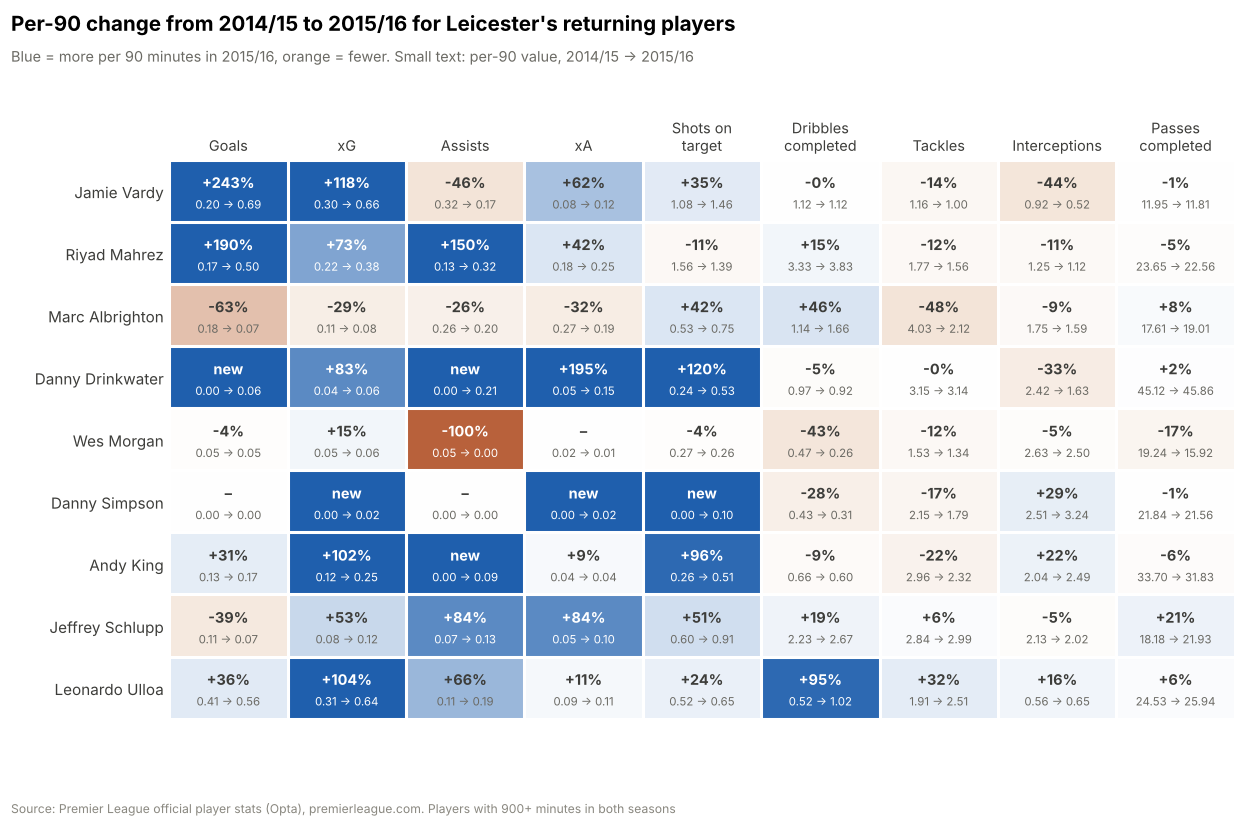

In [4]:
cmap = LinearSegmentedColormap.from_list("updown", ["#B8613B", "#F3E3D6", "#FFFFFF", "#D6E2F1", BLUE])
vals = change.where(before >= 0.02).clip(-100, 100).fillna(pd.DataFrame(np.where(after > before, 100, 0), index=after.index, columns=after.columns))
fig, ax = plt.subplots(figsize=(12.5, 6.6))
ax.imshow(vals.values, cmap=cmap, vmin=-100, vmax=100, aspect="auto")
for i, p in enumerate(RETURNING):
    for j, m in enumerate(METRICS):
        b, a, c = before.loc[p, m], after.loc[p, m], change.loc[p, m]
        pct = "new" if b < 0.02 and a > b else ("–" if b < 0.02 else f"{c:+.0f}%")
        strong = abs(vals.loc[p, m]) > 70
        ax.text(j, i - 0.13, pct, ha="center", va="center", fontsize=9.5, fontweight="bold",
                color="white" if strong else DARK)
        ax.text(j, i + 0.22, f"{b:.2f} → {a:.2f}", ha="center", va="center", fontsize=7.5,
                color="white" if strong else MUTED)
ax.set_xticks(range(len(METRICS)), list(METRICS.values()), fontsize=9.5)
ax.xaxis.tick_top()
ax.set_yticks(range(len(RETURNING)), RETURNING, fontsize=10)
ax.grid(False)
for s in ax.spines.values():
    s.set_visible(False)
ax.set_xticks(np.arange(-0.5, len(METRICS)), minor=True)
ax.set_yticks(np.arange(-0.5, len(RETURNING)), minor=True)
ax.grid(which="minor", color="white", linewidth=2)
ax.tick_params(which="both", length=0)
fig.suptitle("Per-90 change from 2014/15 to 2015/16 for Leicester's returning players", x=0.01, ha="left",
             fontsize=13.5, fontweight="bold", y=1.085)
fig.text(0.01, 1.015, "Blue = more per 90 minutes in 2015/16, orange = fewer. Small text: per-90 value, 2014/15 → 2015/16",
         fontsize=9.5, color=MUTED)
source(fig, "Source: Premier League official player stats (Opta), premierleague.com. Players with 900+ minutes in both seasons")
fig.savefig(FIGS / "13_returning_players_per90_change.png"); plt.show()

### Vardy and Mahrez in detail

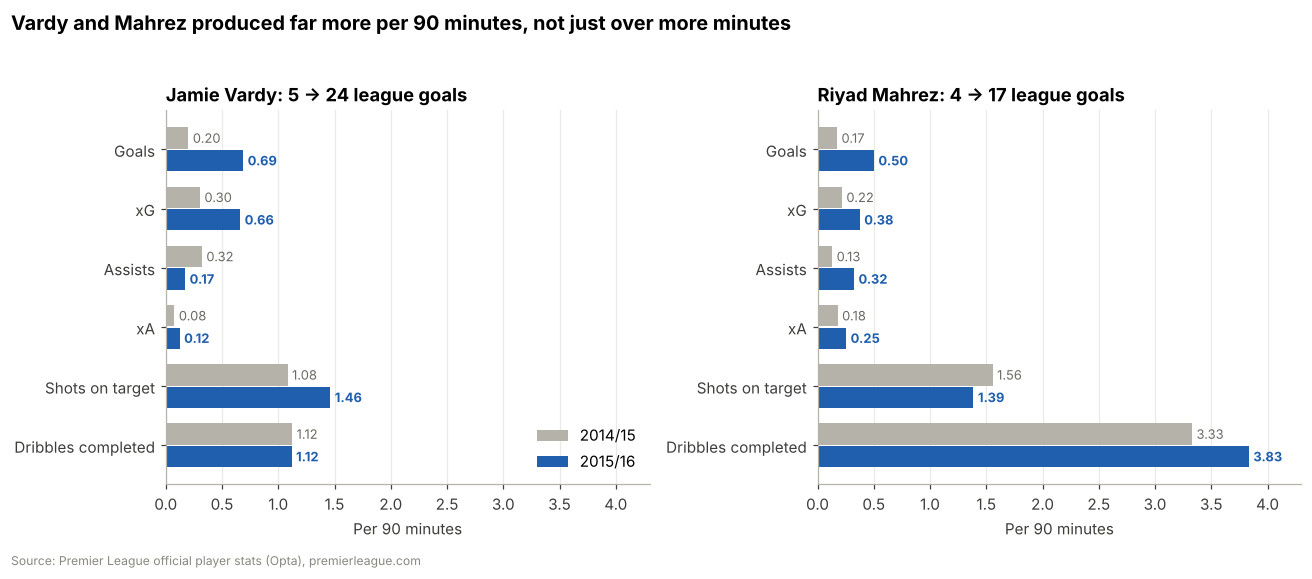

In [5]:
DETAIL = {"goals_p90": "Goals", "xg_p90": "xG", "assists_p90": "Assists", "xa_p90": "xA",
          "shots_on_target_p90": "Shots on target", "dribbles_completed_p90": "Dribbles completed"}
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), sharex=True)
for ax, p in zip(axes, ["Jamie Vardy", "Riyad Mahrez"]):
    y = np.arange(len(DETAIL))[::-1]
    b = before.loc[p, list(DETAIL)].values
    a = after.loc[p, list(DETAIL)].values
    ax.barh(y + 0.19, b, height=0.36, color=GREY, label="2014/15")
    ax.barh(y - 0.19, a, height=0.36, color=BLUE, label="2015/16")
    for yi, bi, ai in zip(y, b, a):
        ax.text(bi + 0.04, yi + 0.19, f"{bi:.2f}", va="center", fontsize=8.5, color=MUTED)
        ax.text(ai + 0.04, yi - 0.19, f"{ai:.2f}", va="center", fontsize=8.5, color=BLUE, fontweight="bold")
    ax.set_yticks(y, list(DETAIL.values()))
    ax.grid(axis="y", visible=False)
    r = pl.set_index(["player", "season"])
    g0, g1 = int(r.loc[(p, "2014/15"), "goals"]), int(r.loc[(p, "2015/16"), "goals"])
    ax.set_title(f"{p}: {g0} → {g1} league goals", fontsize=12)
    ax.set_xlabel("Per 90 minutes")
axes[0].legend(loc="lower right", frameon=False)
axes[0].set_xlim(0, 4.3)
fig.suptitle("Vardy and Mahrez produced far more per 90 minutes, not just over more minutes",
             x=0.01, ha="left", fontsize=13, fontweight="bold", y=1.03)
fig.tight_layout()
source(fig, "Source: Premier League official player stats (Opta), premierleague.com")
fig.savefig(FIGS / "14_vardy_mahrez_2014_15_vs_2015_16.png"); plt.show()

In [6]:
fin = pl[pl.player.isin(["Jamie Vardy", "Riyad Mahrez", "Leonardo Ulloa"])][["player", "season", "goals", "xg"]].copy()
fin["goals_minus_xg"] = (fin.goals - fin.xg).round(2)
fin.sort_values(["player", "season"])

,player,season,goals,xg,goals_minus_xg
0,Jamie Vardy,2014/15,5.0,7.57,-2.57
1,Jamie Vardy,2015/16,24.0,23.07,0.93
10,Leonardo Ulloa,2014/15,11.0,8.38,2.62
24,Leonardo Ulloa,2015/16,6.0,6.89,-0.89
9,Riyad Mahrez,2014/15,4.0,5.01,-1.01
23,Riyad Mahrez,2015/16,17.0,12.72,4.28


**Finishing vs chances.** In 2014/15 Vardy scored 5 from 7.6 xG (−2.6) and Mahrez 4 from 5.0 (−1.0): both *underperformed* their chances.
In 2015/16 Vardy scored 24 from 23.1 xG, roughly in line, so his jump came from **getting into far better positions** (xG per 90 0.30 → 0.66), not lucky finishing.
Mahrez scored 17 from 12.7 xG (+4.3), so part of his jump was elite finishing on top of better chances.

In [7]:
gk = pl[pl.player == "Kasper Schmeichel"].set_index("season")[["appearances", "goals_conceded", "clean_sheets", "saves_made"]]
gk["conceded_per_game"] = (gk.goals_conceded / gk.appearances).round(2)
gk["clean_sheet_rate"] = (gk.clean_sheets / gk.appearances * 100).round(0)
gk

,appearances,goals_conceded,clean_sheets,saves_made,conceded_per_game,clean_sheet_rate
season,,,,,,
2014/15,24.0,37.0,6.0,80.0,1.54,25.0
2015/16,38.0,36.0,15.0,99.0,0.95,39.0


**Schmeichel:** 1.54 goals conceded per game in 2014/15 (24 games), 0.95 in 2015/16 (all 38); clean sheets in 25% of games → 39%.

## Part 2: the summer signings

| Signing | Fee | Compared with (Leicester) |
| --- | --- | --- |
| N'Golo Kanté | £5.6m from Caen | **Esteban Cambiasso** (holding midfielder in 2014/15, left in summer 2015) and **Danny Drinkwater** (his 2015/16 partner) |
| Christian Fuchs | Free from Schalke | **Jeffrey Schlupp** (whom he replaced on the left) and **Danny Simpson** (2015/16 right-back) |
| Shinji Okazaki | £7m from Mainz | **Leonardo Ulloa** (2014/15 top scorer, whose place he took) and **Jamie Vardy** (his strike partner) |
| Robert Huth | £3m from Stoke | **Huth himself in 2014/15**: he joined on loan on 2 February 2015 and played 14 of the run-in games, then signed permanently. Partner: **Wes Morgan** |

Sources for the replacements: Wikipedia articles on [Christian Fuchs](https://en.wikipedia.org/wiki/Christian_Fuchs) ("in place of Jeffrey Schlupp") and [Robert Huth](https://en.wikipedia.org/wiki/Robert_Huth).
Kanté's and Okazaki's predecessors are based on who played those roles most in 2014/15.

In [8]:
r = pl.set_index(["player", "season"])
PANELS = [
    ("N'Golo Kanté", [("Esteban Cambiasso", "2014/15", "replaced"), ("Danny Drinkwater", "2015/16", "partner")],
     {"total_tackles_p90": "Tackles", "interceptions_p90": "Interceptions", "duels_won_p90": "Duels won",
      "dribbles_completed_p90": "Dribbles completed", "passes_completed_p90": "Passes completed"}),
    ("Christian Fuchs", [("Jeffrey Schlupp", "2014/15", "replaced"), ("Danny Simpson", "2015/16", "other full-back")],
     {"total_tackles_p90": "Tackles", "interceptions_p90": "Interceptions", "duels_won_p90": "Duels won",
      "xa_p90": "xA", "passes_completed_p90": "Passes completed"}),
    ("Shinji Okazaki", [("Leonardo Ulloa", "2014/15", "replaced"), ("Jamie Vardy", "2015/16", "partner")],
     {"total_tackles_p90": "Tackles", "duels_won_p90": "Duels won", "aerial_duels_won_p90": "Aerial duels won",
      "xg_p90": "xG", "passes_completed_p90": "Passes completed"}),
    ("Robert Huth", [("Robert Huth", "2014/15", "on loan, mostly Leicester"), ("Wes Morgan", "2015/16", "partner")],
     {"interceptions_p90": "Interceptions", "blocks_p90": "Blocks", "aerial_duels_won_p90": "Aerial duels won",
      "duels_won_p90": "Duels won", "total_tackles_p90": "Tackles"}),
]

rows = []
for signing, comps, mets in PANELS:
    people = [(signing, "2015/16", "signing")] + comps
    for m, label in mets.items():
        rows.append({"signing": signing, "metric": label,
                     **{f"{p} {s}" if p != signing or s != "2015/16" else "signing 2015/16": round(r.loc[(p, s), m], 2)
                        for p, s, _ in people}})
compare = pd.DataFrame(rows)
for signing, g in compare.groupby("signing", sort=False):
    print()
    print(f"{signing} (per 90)")
    print(g.drop(columns="signing").dropna(axis=1).to_string(index=False))


N'Golo Kanté (per 90)
            metric  signing 2015/16  Esteban Cambiasso 2014/15  Danny Drinkwater 2015/16
           Tackles             5.22                       2.60                      3.14
     Interceptions             4.65                       2.49                      1.63
         Duels won             8.25                       5.05                      5.66
Dribbles completed             1.40                       0.56                      0.92
  Passes completed            35.40                      30.76                     45.86

Christian Fuchs (per 90)
          metric  signing 2015/16  Jeffrey Schlupp 2014/15  Danny Simpson 2015/16
         Tackles             3.29                     2.84                   1.79
   Interceptions             3.25                     2.13                   3.24
       Duels won             5.55                     8.19                   4.51
              xA             0.11                     0.05                   0.02
Passes 

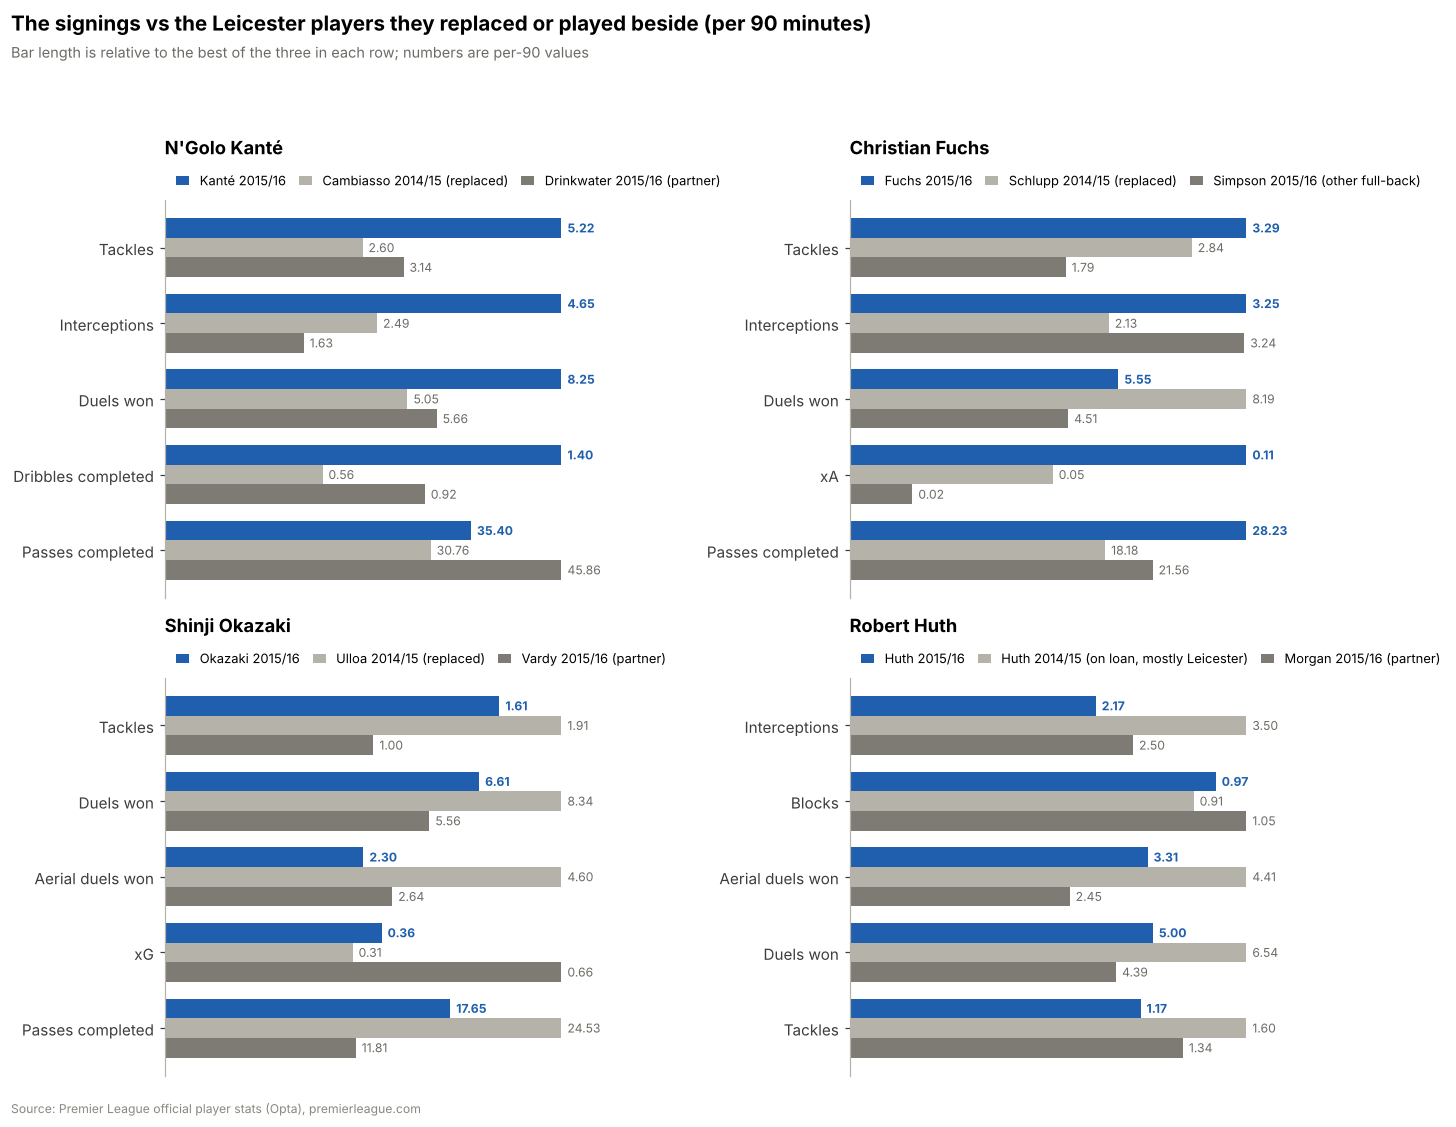

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9.5))
colors = [BLUE, GREY, "#7D7B74"]
for ax, (signing, comps, mets) in zip(axes.flat, PANELS):
    people = [(signing, "2015/16", "")] + comps
    labels = list(mets.values())
    y = np.arange(len(labels))[::-1]
    h = 0.26
    for k, (p, s, role) in enumerate(people):
        vals = np.array([r.loc[(p, s), m] for m in mets])
        best = np.array([max(r.loc[(pp, ss), m] for pp, ss, _ in people) for m in mets])
        rel = np.where(best > 0, vals / best, 0)
        name = p.split()[-1] if p != "N'Golo Kanté" else "Kanté"
        lab = f"{name} {s}" + (f" ({role})" if role else "")
        ax.barh(y + h * (1 - k), rel, height=h, color=colors[k], label=lab)
        for yi, rv, v in zip(y, rel, vals):
            ax.text(rv + 0.015, yi + h * (1 - k), f"{v:.2f}", va="center", fontsize=8,
                    color=BLUE if k == 0 else MUTED, fontweight="bold" if k == 0 else "normal")
    ax.set_yticks(y, labels)
    ax.set_xlim(0, 1.18)
    ax.set_xticks([])
    ax.grid(False)
    ax.spines["bottom"].set_visible(False)
    ax.set_title(signing, fontsize=12, pad=30)
    ax.legend(loc="lower left", bbox_to_anchor=(0, 1.0), ncol=3, frameon=False, fontsize=8.5,
              handlelength=1, columnspacing=1)
fig.suptitle("The signings vs the Leicester players they replaced or played beside (per 90 minutes)",
             x=0.01, ha="left", fontsize=13.5, fontweight="bold", y=1.035)
fig.text(0.01, 0.99, "Bar length is relative to the best of the three in each row; numbers are per-90 values",
         fontsize=9.5, color=MUTED)
fig.tight_layout(rect=(0, 0, 1, 0.97))
source(fig, "Source: Premier League official player stats (Opta), premierleague.com")
fig.savefig(FIGS / "15_signings_vs_leicester_teammates.png"); plt.show()

## Part 3: the signings vs the whole Premier League (StatsBomb)

Percentile among all players in the same position group with 900+ minutes in 2015/16 (100 = best), per 90 minutes.
Weak spots are shown as well as strengths.

In [10]:
DATA = ROOT / "data" / "processed" / "2_27"
events = pd.read_parquet(DATA / "events.parquet")
players = pd.read_parquet(DATA / "player_season.parquet").set_index("player_id")
shots = events[events.type == "Shot"].assign(xg=lambda d: d.shot_statsbomb_xg.astype(float),
                                             goal=lambda d: d.shot_outcome == "Goal")
f = lambda mask: events[mask].groupby("player_id").size()
tackles = (events.type == "Duel") & (events.duel_type == "Tackle")
stats = players.join(pd.DataFrame({
    "goals": shots.groupby("player_id").goal.sum(),
    "np_xg": shots[shots.shot_type != "Penalty"].groupby("player_id").xg.sum(),
    "assists": f(events.pass_goal_assist),
    "chances_created": f(events.pass_shot_assist | events.pass_goal_assist),
    "tackles": f(tackles), "interceptions": f(events.type == "Interception"),
    "ball_recoveries": f(events.type == "Ball Recovery"), "pressures": f(events.type == "Pressure"),
    "pressures_att_third": f((events.type == "Pressure") & (events.start_x >= 80)),
    "clearances": f(events.type == "Clearance"), "blocks": f(events.type == "Block"),
    "tackles_won": f(tackles & events.duel_outcome.isin(["Won", "Success In Play", "Success Out"])),
    "progressive_passes": f((events.type == "Pass") & events.pass_outcome.isna()
                            & ((events.pass_end_x - events.start_x) >= 10) & (events.pass_end_x >= 40)),
})).fillna(0)
regulars = stats[(stats.minutes >= 900) & (stats.position_group != "Goalkeeper")]
metric_cols = [c for c in ["goals", "np_xg", "assists", "chances_created", "tackles", "interceptions", "ball_recoveries",
               "pressures", "pressures_att_third", "clearances", "blocks", "tackles_won", "progressive_passes"]]
p90 = regulars[metric_cols].div(regulars.minutes, axis=0) * 90
pct = (p90.groupby(regulars.position_group).rank(pct=True) * 100).round(0)
pid = lambda n: regulars.index[regulars.display_name == n][0]

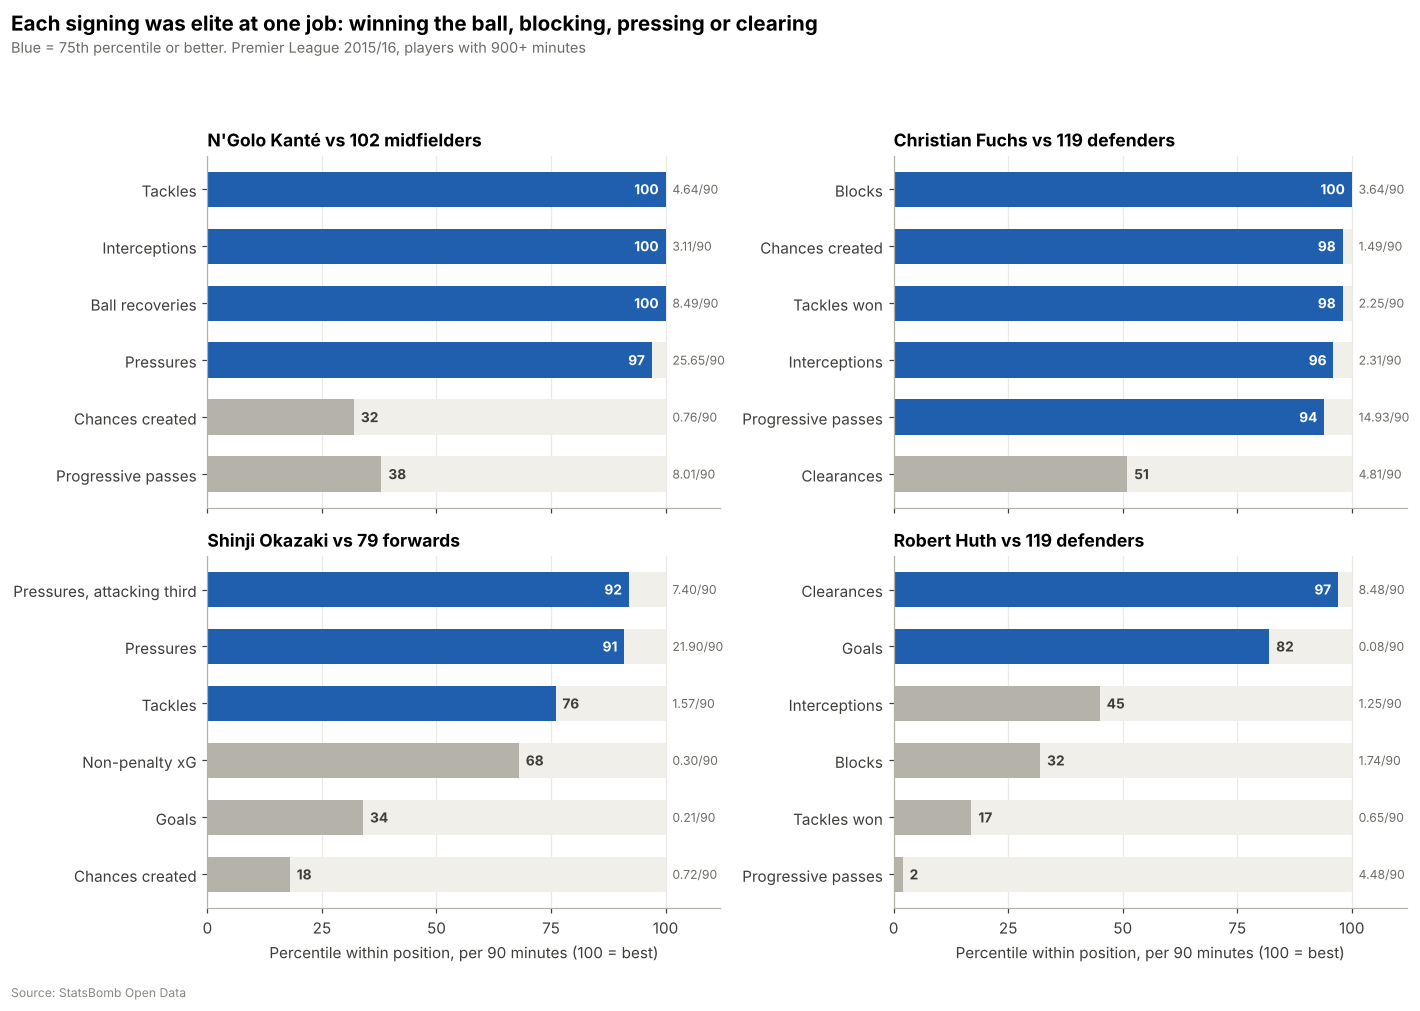

In [11]:
LEAGUE = [
    ("N'Golo Kanté", {"tackles": "Tackles", "interceptions": "Interceptions", "ball_recoveries": "Ball recoveries",
                      "pressures": "Pressures", "chances_created": "Chances created", "progressive_passes": "Progressive passes"}),
    ("Christian Fuchs", {"blocks": "Blocks", "chances_created": "Chances created", "tackles_won": "Tackles won",
                         "interceptions": "Interceptions", "progressive_passes": "Progressive passes", "clearances": "Clearances"}),
    ("Shinji Okazaki", {"pressures_att_third": "Pressures, attacking third", "pressures": "Pressures", "tackles": "Tackles",
                        "np_xg": "Non-penalty xG", "goals": "Goals", "chances_created": "Chances created"}),
    ("Robert Huth", {"clearances": "Clearances", "goals": "Goals", "interceptions": "Interceptions",
                     "blocks": "Blocks", "tackles_won": "Tackles won", "progressive_passes": "Progressive passes"}),
]
fig, axes = plt.subplots(2, 2, figsize=(13, 8.5), sharex=True)
for ax, (name, mets) in zip(axes.flat, LEAGUE):
    i = pid(name)
    group = regulars.loc[i, "position_group"]
    n = int((regulars.position_group == group).sum())
    labels = list(mets.values())[::-1]
    vals = [pct.loc[i, m] for m in list(mets)[::-1]]
    y = np.arange(len(labels))
    ax.barh(y, [100] * len(y), color="#F1EFEA", height=0.62)
    ax.barh(y, vals, color=[BLUE if v >= 75 else GREY for v in vals], height=0.62)
    for yi, v, m in zip(y, vals, list(mets)[::-1]):
        ax.text(v + 1.5 if v < 88 else v - 1.5, yi, f"{v:.0f}", va="center", ha="left" if v < 88 else "right",
                fontsize=9, fontweight="bold", color=DARK if v < 88 else "white")
        ax.text(101.5, yi, f"{p90.loc[i, m]:.2f}/90", va="center", fontsize=8, color=MUTED)
    ax.set_yticks(y, labels)
    ax.set_xlim(0, 112)
    ax.set_xticks([0, 25, 50, 75, 100])
    ax.grid(axis="y", visible=False)
    ax.set_title(f"{name} vs {n} {group.lower()}s", fontsize=11.5)
for ax in axes[-1]:
    ax.set_xlabel("Percentile within position, per 90 minutes (100 = best)")
fig.suptitle("Each signing was elite at one job: winning the ball, blocking, pressing or clearing",
             x=0.01, ha="left", fontsize=13.5, fontweight="bold", y=1.035)
fig.text(0.01, 0.99, "Blue = 75th percentile or better. Premier League 2015/16, players with 900+ minutes",
         fontsize=9.5, color=MUTED)
fig.tight_layout(rect=(0, 0, 1, 0.97))
source(fig, "Source: StatsBomb Open Data")
fig.savefig(FIGS / "16_signings_league_percentiles.png"); plt.show()

In [12]:
outfield = stats[stats.position_group != "Goalkeeper"]
def rank(name, col):
    i = outfield.index[outfield.display_name == name][0]
    return int(outfield[col].rank(ascending=False, method="min").loc[i]), int(outfield.loc[i, col])
pd.DataFrame([
    ("N'Golo Kanté", "Tackles", *rank("N'Golo Kanté", "tackles")),
    ("N'Golo Kanté", "Interceptions", *rank("N'Golo Kanté", "interceptions")),
    ("N'Golo Kanté", "Ball recoveries", *rank("N'Golo Kanté", "ball_recoveries")),
    ("Christian Fuchs", "Blocks", *rank("Christian Fuchs", "blocks")),
    ("Robert Huth", "Clearances", *rank("Robert Huth", "clearances")),
    ("Shinji Okazaki", "Pressures in attacking third", *rank("Shinji Okazaki", "pressures_att_third")),
], columns=["player", "season total", "league rank (outfield)", "count"])

,player,season total,league rank (outfield),count
0,N'Golo Kanté,Tackles,1,164
1,N'Golo Kanté,Interceptions,1,110
2,N'Golo Kanté,Ball recoveries,1,300
3,Christian Fuchs,Blocks,1,115
4,Robert Huth,Clearances,2,312
5,Shinji Okazaki,Pressures in attacking third,14,174


## Summary

**Returning players (Opta data, per 90 minutes)**
- **Vardy:** goals per 90 went from 0.20 to 0.69 and xG per 90 from 0.30 to 0.66 (assists fell from 8 to 6). In 2014/15 he scored fewer goals than his chances were worth; in 2015/16 he finished in line with them. The gain came from much better chances.
- **Mahrez:** goals per 90 went from 0.17 to 0.50 and assists from 0.13 to 0.32, with more dribbles completed and shots on target. He scored 4.3 goals more than his xG.
- **Drinkwater:** assists per 90 went from 0 to 0.21 and xA from 0.05 to 0.15, while his tackling held at about 3.1 per 90 over twice the minutes. He made the most passes in the squad (1,984), the distributor next to Kanté.
- **Albrighton, Drinkwater and Simpson** roughly doubled their minutes; **Ulloa** lost his place (2,407 → 968 minutes) to Okazaki.
- **Schmeichel:** goals conceded per game fell from 1.54 to 0.95.

**Signings**
- **Kanté** made about twice as many tackles and interceptions per 90 as Cambiasso, the man he replaced, and was 100th percentile among the league's midfielders for both.
- **Fuchs** made more tackles, interceptions and passes per 90 than Schlupp, the more attacking player he replaced at left-back, and more than doubled his xA (0.05 → 0.11). Schlupp won more duels. Against the league, Fuchs led all defenders in blocks per 90 and was 98th percentile for chances created.
- **Okazaki** is the honest exception in the Opta numbers: per 90 he won fewer duels (6.6 vs 8.3) and made fewer tackles (1.6 vs 1.9) than Ulloa had in 2014/15, with slightly more xG (0.36 vs 0.31). His value shows up in pressing, which only StatsBomb measures: 91st–92nd percentile among forwards (Part 3).
- **Huth** was already part of the 2015 escape on loan. In 2015/16 he won more aerial duels per 90 than Morgan (3.3 vs 2.5) and was 97th percentile among defenders for clearances (2nd-most in the league), with weak passing and tackling numbers. His per-90 interceptions fell from 3.5 on loan to 2.2.

**Limitations:** two data providers (Opta for season-on-season, StatsBomb for league percentiles) with slightly different event definitions, so their numbers aren't mixed. Huth's 2014/15 line includes one Stoke appearance. 2014/15 role assignments (who replaced whom) are judgement calls, explained above.

### Sources
- Premier League official player stats, e.g. [Jamie Vardy](https://www.premierleague.com/en/players/101668/jamie-vardy/stats?season=2014); the URL for every player is built from the IDs in `src/football_analytics/pl_stats.py`
- [Christian Fuchs, Wikipedia](https://en.wikipedia.org/wiki/Christian_Fuchs) · [Robert Huth, Wikipedia](https://en.wikipedia.org/wiki/Robert_Huth)
- StatsBomb Open Data